# Group 3: Student Dropout Risk — Implementation Notebook (FUSE-AI-201, Module 5)
**Goal:** predict, at the end of semester one, whether a student will drop out (1 = Dropout, 0 = Graduate or Enrolled).
**Data:** UCI "Predict Students' Dropout and Academic Success" (dataset 697). **Split:** 70/15/15 stratified, `random_state=42`.

| # | Task |
|---|---|
| 1 | Load and inspect the data |
| 2 | Prevent leakage and split the data |
| 3 | Baseline model |
| 4 | Candidate models, cross-validation and threshold trade-offs |
| 5 | Hyperparameter tuning |
| 6 | Final model, threshold and one-time test evaluation |
| 7 | Save the model and metadata, complete the metadata, record the run in MLflow |
| 8 | Error and subgroup analysis, evaluation curves, hand-off |

Cell outputs below are from the original run and are kept unchanged.

## Task 1: Load and inspect the data
Loads the dataset from the UCI repository. It has 4,424 students and 36 input columns plus `Target` (Graduate 2,209, Dropout 1,421, Enrolled 794). There are no missing values and no duplicate rows.

In [1]:
!pip install ucimlrepo -q

from ucimlrepo import fetch_ucirepo
import pandas as pd

data = fetch_ucirepo(id=697)   # Predict Students' Dropout and Academic Success
df = pd.concat([data.data.features, data.data.targets], axis=1)

print("Shape:", df.shape)                     # expect about (4424, 37): 36 features + target
print("\nTarget counts:\n", df["Target"].value_counts())
print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nColumns:")
for c in df.columns:
    print(" -", c)

Shape: (4424, 37)

Target counts:
 Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Missing values: 0
Duplicate rows: 0

Columns:
 - Marital Status
 - Application mode
 - Application order
 - Course
 - Daytime/evening attendance
 - Previous qualification
 - Previous qualification (grade)
 - Nacionality
 - Mother's qualification
 - Father's qualification
 - Mother's occupation
 - Father's occupation
 - Admission grade
 - Displaced
 - Educational special needs
 - Debtor
 - Tuition fees up to date
 - Gender
 - Scholarship holder
 - Age at enrollment
 - International
 - Curricular units 1st sem (credited)
 - Curricular units 1st sem (enrolled)
 - Curricular units 1st sem (evaluations)
 - Curricular units 1st sem (approved)
 - Curricular units 1st sem (grade)
 - Curricular units 1st sem (without evaluations)
 - Curricular units 2nd sem (credited)
 - Curricular units 2nd sem (enrolled)
 - Curricular units 2nd sem (evaluations)
 - Curricular units 2nd sem (

## Tasks 2 and 3: Prevent leakage, split the data, and fit a baseline
**Leakage control:** the six `2nd sem` columns are excluded because they are not known at the end of semester one. An `assert` checks that none remain, leaving 30 features.
**Split:** the test set is held out first, then validation is taken from the rest (3,098 train / 662 validation / 664 test, dropout share about 32% in each).
**Baseline (E001):** a logistic regression with scaling only, with the scaler inside the pipeline so it is fit on training data only. Validation result: dropout recall 0.77, precision 0.75, ROC-AUC 0.893. Later models are compared against this.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

# Exclude semester 2 columns (prediction point is the end of semester 1)
sem2_cols = [c for c in df.columns if "2nd sem" in c.lower()]
print("Excluded semester 2 columns:", sem2_cols)

feature_cols = [c for c in df.columns if c not in sem2_cols and c != "Target"]
assert not any("2nd sem" in c.lower() for c in feature_cols), "Leakage: semester 2 column found"
print(f"{len(feature_cols)} features allowed\n")

X = df[feature_cols]
y = (df["Target"] == "Dropout").astype(int)   # 1 = Dropout, 0 = Graduate or Enrolled

# 70/15/15 stratified split: hold out test first
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.176, random_state=42, stratify=y_temp)

print(f"Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")
print("Dropout share ->",
      f"train {y_train.mean():.3f}, val {y_val.mean():.3f}, test {y_test.mean():.3f}")

# Baseline: scaler inside the pipeline, so it is fit on training data only
baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
baseline.fit(X_train, y_train)

# Evaluate on VALIDATION only (the test set stays untouched until the end)
val_prob = baseline.predict_proba(X_val)[:, 1]
val_pred = (val_prob >= 0.5).astype(int)
print("\nBaseline (logistic regression) on validation set:")
print(classification_report(y_val, val_pred, target_names=["Not Dropout", "Dropout"]))
print(f"ROC-AUC: {roc_auc_score(y_val, val_prob):.3f}")

Excluded semester 2 columns: ['Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)']
30 features allowed

Train: 3098, Val: 662, Test: 664
Dropout share -> train 0.321, val 0.322, test 0.321

Baseline (logistic regression) on validation set:
              precision    recall  f1-score   support

 Not Dropout       0.89      0.88      0.88       449
     Dropout       0.75      0.77      0.76       213

    accuracy                           0.84       662
   macro avg       0.82      0.82      0.82       662
weighted avg       0.84      0.84      0.84       662

ROC-AUC: 0.893


## Task 4a: Candidate models with proper encoding
The 30 features are grouped as 9 categorical, 8 binary and 13 numeric. Categorical codes are one-hot encoded (unseen categories are ignored) and numeric columns are scaled, all inside the pipeline.
Three candidates are compared on the validation set: logistic regression (E002), Random Forest (E003) and XGBoost (E004). Proper encoding raised the logistic regression's recall from 0.765 to 0.817. Random Forest had the lowest recall (0.657) at the default 0.5 threshold. XGBoost had the highest validation ROC-AUC (0.910), a single-split result checked in the next cell.

In [3]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score, average_precision_score
from xgboost import XGBClassifier

# Column groups (numeric codes that are really categories get one-hot encoded)
categorical = ["Marital Status", "Application mode", "Course", "Previous qualification",
               "Nacionality", "Mother's qualification", "Father's qualification",
               "Mother's occupation", "Father's occupation"]
binary = ["Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
          "Tuition fees up to date", "Gender", "Scholarship holder", "International"]
numeric = [c for c in feature_cols if c not in categorical + binary]

# Safety check: every allowed feature is assigned to exactly one group
assert set(categorical + binary + numeric) == set(feature_cols)
print(f"{len(categorical)} categorical, {len(binary)} binary, {len(numeric)} numeric")

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
        ("bin", "passthrough", binary),
    ])

neg_pos = (y_train == 0).sum() / (y_train == 1).sum()   # imbalance ratio for XGBoost

models = {
    "E002 LogReg + proper encoding": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "E003 Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                 random_state=42, n_jobs=-1),
    "E004 XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                                  subsample=0.8, colsample_bytree=0.8,
                                  scale_pos_weight=neg_pos, eval_metric="logloss",
                                  random_state=42),
}

log = []
for name, clf in models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("model", clf)])
    pipe.fit(X_train, y_train)                       # preprocessing fit on train only
    prob = pipe.predict_proba(X_val)[:, 1]
    pred = (prob >= 0.5).astype(int)
    log.append({
        "experiment": name,
        "recall_dropout": recall_score(y_val, pred),
        "precision_dropout": precision_score(y_val, pred),
        "f1_dropout": f1_score(y_val, pred),
        "roc_auc": roc_auc_score(y_val, prob),
        "pr_auc": average_precision_score(y_val, prob),
    })

# Add E001 (the quick baseline from before) for comparison
log.insert(0, {"experiment": "E001 LogReg, scaled only",
               "recall_dropout": recall_score(y_val, val_pred),
               "precision_dropout": precision_score(y_val, val_pred),
               "f1_dropout": f1_score(y_val, val_pred),
               "roc_auc": roc_auc_score(y_val, val_prob),
               "pr_auc": average_precision_score(y_val, val_prob)})

experiment_log = pd.DataFrame(log).round(3)
print(experiment_log.to_string(index=False))

9 categorical, 8 binary, 13 numeric
                   experiment  recall_dropout  precision_dropout  f1_dropout  roc_auc  pr_auc
     E001 LogReg, scaled only           0.765              0.748       0.756    0.893   0.844
E002 LogReg + proper encoding           0.817              0.728       0.770    0.902   0.859
           E003 Random Forest           0.657              0.838       0.737    0.896   0.848
                 E004 XGBoost           0.770              0.766       0.768    0.910   0.870


## Task 4b: Five-fold cross-validation
A single validation split can mislead, so each candidate is also scored with stratified 5-fold cross-validation on the training data, together with a majority-class dummy (AUC 0.500). Logistic regression (0.902 ± 0.005), XGBoost (0.899 ± 0.007) and Random Forest (0.894 ± 0.009) are within about one fold-spread of each other. The single-split lead for XGBoost does not hold up, so the models are effectively tied on ranking quality.

In [4]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer, precision_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "roc_auc": "roc_auc",
    "recall": "recall",
    "precision": make_scorer(precision_score, zero_division=0),
    "f1": "f1",
}

candidates = {"E000 Majority class": DummyClassifier(strategy="most_frequent"), **models}

rows = []
for name, clf in candidates.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("model", clf)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    row = {"experiment": name}
    for m in scoring:
        scores = res[f"test_{m}"]
        row[m] = f"{scores.mean():.3f} ± {scores.std():.3f}"
    rows.append(row)

print(pd.DataFrame(rows).to_string(index=False))

                   experiment       roc_auc        recall     precision            f1
          E000 Majority class 0.500 ± 0.000 0.000 ± 0.000 0.000 ± 0.000 0.000 ± 0.000
E002 LogReg + proper encoding 0.902 ± 0.005 0.792 ± 0.022 0.740 ± 0.013 0.765 ± 0.012
           E003 Random Forest 0.894 ± 0.009 0.638 ± 0.024 0.843 ± 0.026 0.726 ± 0.024
                 E004 XGBoost 0.899 ± 0.007 0.756 ± 0.029 0.757 ± 0.011 0.756 ± 0.019


## Task 4c: Precision at matched recall
The project needs a high recall of dropouts, so models are compared by precision at the same recall level using out-of-fold predictions. At recall 0.75 / 0.80 / 0.85, logistic regression has precision 0.801 / 0.732 / 0.668, XGBoost 0.767 / 0.735 / 0.647 and Random Forest 0.750 / 0.701 / 0.626. Logistic regression is best or tied, and it is the simplest and most interpretable model.

In [5]:
import numpy as np
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

targets = [0.75, 0.80, 0.85]
pr_rows = []

for name, clf in models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("model", clf)])
    prob = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    prec, rec, thr = precision_recall_curve(y_train, prob)

    row = {"experiment": name}
    for t in targets:
        ok = rec[:-1] >= t                       # operating points that reach this recall
        if ok.any():
            idx = np.where(ok)[0][np.argmax(prec[:-1][ok])]
            row[f"precision @ recall {t:.2f}"] = round(prec[idx], 3)
            if t == 0.80:
                row["threshold @ recall 0.80"] = round(thr[idx], 3)
    pr_rows.append(row)

print(pd.DataFrame(pr_rows).to_string(index=False))

                   experiment  precision @ recall 0.75  precision @ recall 0.80  threshold @ recall 0.80  precision @ recall 0.85
E002 LogReg + proper encoding                    0.801                    0.732                    0.488                    0.668
           E003 Random Forest                    0.750                    0.701                    0.320                    0.626
                 E004 XGBoost                    0.767                    0.735                    0.425                    0.647


## Task 5: Hyperparameter tuning
XGBoost is tuned with 25 random configurations and logistic regression's regularisation strength C with a grid, both with 5-fold CV on ROC-AUC. Tuned XGBoost reaches 0.899 and tuned logistic regression 0.902 (best C = 0.3). Tuning did not change the ranking, so logistic regression (C = 0.3) is kept as the final model.

In [6]:
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from scipy.stats import randint, uniform

# --- Tune XGBoost (25 random configurations, 5-fold CV) ---
xgb_pipe = Pipeline([
    ("prep", make_preprocessor()),
    ("model", XGBClassifier(scale_pos_weight=neg_pos, eval_metric="logloss", random_state=42)),
])
xgb_space = {
    "model__n_estimators": randint(100, 500),
    "model__max_depth": randint(2, 6),
    "model__learning_rate": uniform(0.01, 0.10),
    "model__subsample": uniform(0.6, 0.4),
    "model__colsample_bytree": uniform(0.5, 0.5),
    "model__min_child_weight": randint(1, 10),
    "model__reg_lambda": uniform(1, 9),
}
xgb_search = RandomizedSearchCV(xgb_pipe, xgb_space, n_iter=25, scoring="roc_auc",
                                cv=cv, random_state=42, n_jobs=-1)
xgb_search.fit(X_train, y_train)
print(f"Tuned XGBoost  CV AUC: {xgb_search.best_score_:.3f}")
print("Best params:", xgb_search.best_params_)

# --- Tune logistic regression's regularisation strength ---
lr_pipe = Pipeline([
    ("prep", make_preprocessor()),
    ("model", LogisticRegression(max_iter=3000, class_weight="balanced")),
])
lr_search = GridSearchCV(lr_pipe, {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3]},
                         scoring="roc_auc", cv=cv, n_jobs=-1)
lr_search.fit(X_train, y_train)
print(f"\nTuned LogReg   CV AUC: {lr_search.best_score_:.3f}")
print("Best params:", lr_search.best_params_)

Tuned XGBoost  CV AUC: 0.899
Best params: {'model__colsample_bytree': np.float64(0.5610439773503366), 'model__learning_rate': np.float64(0.04562978380769749), 'model__max_depth': 3, 'model__min_child_weight': 1, 'model__n_estimators': 484, 'model__reg_lambda': np.float64(3.051416462877475), 'model__subsample': np.float64(0.7708431154505025)}

Tuned LogReg   CV AUC: 0.902
Best params: {'model__C': 0.3}


## Task 6: Final model, threshold and one-time test evaluation
1. The final logistic regression is fit on the training data.
2. The decision threshold is chosen on the **validation** set as the point with the highest precision subject to recall of at least 0.80. This gives 0.519.
3. The **test set is used once**, at this threshold: accuracy 0.88, dropout precision 0.79, recall 0.83, F1 0.81, ROC-AUC 0.922. The confusion matrix is 405 true negatives, 46 false positives, 37 false negatives and 176 true positives.
4. Recall is checked by gender code, scholarship holder, displaced and age band (small groups, so interpret cautiously), and the largest coefficients are listed (positive values raise dropout risk).

Threshold from validation: 0.519 (val precision 0.737, val recall 0.803)

TEST SET RESULTS
              precision    recall  f1-score   support

 Not Dropout       0.92      0.90      0.91       451
     Dropout       0.79      0.83      0.81       213

    accuracy                           0.88       664
   macro avg       0.85      0.86      0.86       664
weighted avg       0.88      0.88      0.88       664

ROC-AUC: 0.922


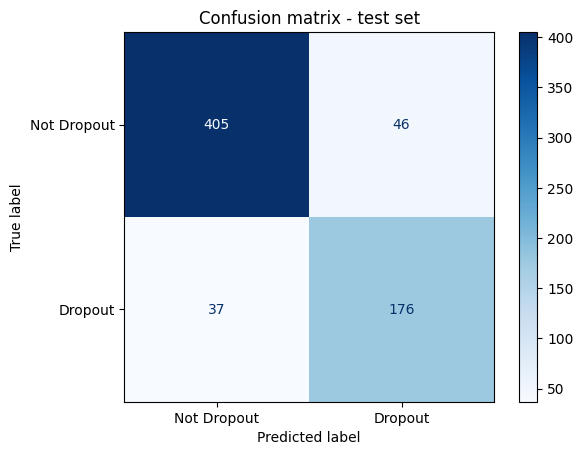


--- Gender ---
 Gender   n  dropouts  recall  flagged_share
      0 421       100   0.770          0.235
      1 243       113   0.876          0.506

--- Scholarship holder ---
 Scholarship holder   n  dropouts  recall  flagged_share
                  0 496       195   0.846          0.417
                  1 168        18   0.611          0.089

--- Displaced ---
 Displaced   n  dropouts  recall  flagged_share
         0 294       105   0.876          0.391
         1 370       108   0.778          0.289

--- age_band ---
age_band   n  dropouts  recall  flagged_share
    <=19 312        58   0.759          0.205
   20-24 174        54   0.796          0.293
     25+ 178       101   0.881          0.601

Lowest dropout risk:
 bin__Tuition fees up to date               -2.17
num__Curricular units 1st sem (approved)   -2.02
cat__Mother's occupation_191               -0.95
cat__Course_171                            -0.88
cat__Mother's qualification_4              -0.68
bin__Scholarship 

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_recall_curve, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score)

final = Pipeline([("prep", make_preprocessor()),
                  ("model", LogisticRegression(C=0.3, max_iter=3000, class_weight="balanced"))])
final.fit(X_train, y_train)

# 1. Threshold chosen on validation data (never on the test set)
val_prob_final = final.predict_proba(X_val)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, val_prob_final)
ok = rec[:-1] >= 0.80
idx = np.where(ok)[0][np.argmax(prec[:-1][ok])]
threshold = float(thr[idx])
print(f"Threshold from validation: {threshold:.3f} "
      f"(val precision {prec[idx]:.3f}, val recall {rec[idx]:.3f})")

# 2. One-time test evaluation
test_prob = final.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= threshold).astype(int)
print("\nTEST SET RESULTS")
print(classification_report(y_test, test_pred, target_names=["Not Dropout", "Dropout"]))
print(f"ROC-AUC: {roc_auc_score(y_test, test_prob):.3f}")

ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred),
                       display_labels=["Not Dropout", "Dropout"]).plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix - test set")
plt.show()

# 3. Subgroup check (recall = share of real dropouts caught in each group)
test_df = X_test.copy()
test_df["y"] = y_test.values
test_df["pred"] = test_pred
test_df["age_band"] = pd.cut(test_df["Age at enrollment"], [0, 19, 24, 100],
                             labels=["<=19", "20-24", "25+"])

def subgroup_table(col):
    rows = []
    for val, d in test_df.groupby(col, observed=True):
        pos = d["y"] == 1
        rows.append({col: val, "n": len(d), "dropouts": int(pos.sum()),
                     "recall": round((d.loc[pos, "pred"] == 1).mean(), 3) if pos.any() else np.nan,
                     "flagged_share": round(d["pred"].mean(), 3)})
    return pd.DataFrame(rows)

for col in ["Gender", "Scholarship holder", "Displaced", "age_band"]:
    print(f"\n--- {col} ---")
    print(subgroup_table(col).to_string(index=False))

# 4. Strongest coefficients (positive raises dropout risk)
names = final.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(final.named_steps["model"].coef_[0], index=names).sort_values()
print("\nLowest dropout risk:\n", coefs.head(8).round(2))
print("\nHighest dropout risk:\n", coefs.tail(8).round(2))

## Task 7: Save the model and metadata
Saves the fitted pipeline to `model_artifacts/dropout_pipeline_v1.joblib` and a `metadata_v1.json` with the version, model type, prediction point, the 30 input features, the 0.519 threshold, the number of training samples and the excluded columns. A sanity check reloads the model and confirms that predicted probabilities fall between 0 and 1.

In [8]:
import joblib, json, os
from datetime import datetime

os.makedirs("model_artifacts", exist_ok=True)
joblib.dump(final, "model_artifacts/dropout_pipeline_v1.joblib")

metadata = {
    "version": "v1",
    "saved": datetime.now().strftime("%Y-%m-%d %H:%M"),
    "model_type": "LogisticRegression (C=0.3, class_weight=balanced) in a scikit-learn Pipeline",
    "task": "binary_classification (1 = Dropout)",
    "prediction_point": "end of semester 1",
    "input_features": feature_cols,
    "threshold": threshold,
    "training_samples": len(X_train),
    "excluded_columns": sem2_cols,
}
with open("model_artifacts/metadata_v1.json", "w") as f:
    json.dump(metadata, f, indent=2)

# Sanity check before handing off
loaded = joblib.load("model_artifacts/dropout_pipeline_v1.joblib")
probs = loaded.predict_proba(X_val.iloc[:5])[:, 1]
print("Sanity check:", probs.round(3), "| all in [0,1]:", bool(((probs >= 0) & (probs <= 1)).all()))

Sanity check: [0.674 0.76  0.265 0.992 0.418] | all in [0,1]: True


## Task 7b: Complete the metadata
Adds the training-data feature averages and the scikit-learn version to `metadata_v1.json`. The app and API use the averages to explain each score relative to the average student, and the version lets them warn about a mismatch. The model file itself is not changed.

In [9]:
import json, sklearn

# Add the training-data feature averages and the scikit-learn version to the saved metadata.
# The app and API need feature_means to explain scores relative to the average student.
prep = final.named_steps["prep"]
means = prep.transform(X_train).mean(axis=0)
meta_path = "model_artifacts/metadata_v1.json"
meta = json.load(open(meta_path))
meta["feature_means"] = {n: round(float(m), 6) for n, m in zip(prep.get_feature_names_out(), means)}
meta["sklearn_version"] = sklearn.__version__
with open(meta_path, "w") as fh:
    json.dump(meta, fh, indent=2)
print("metadata updated | sklearn", meta["sklearn_version"], "| feature_means:", len(meta["feature_means"]))

metadata updated | sklearn 1.6.1 | feature_means: 221


## Task 7c: Record the final model in MLflow
Logs the final model's parameters, library versions, data hash, model-file fingerprint (SHA-256), validation and test metrics, and the model and metadata files in an MLflow run, using a local SQLite store. This lets anyone check later which exact model was evaluated and which versions produced it. The test metrics are recorded for the record and were not used to select the model.

In [10]:
!pip install mlflow -q

import mlflow, hashlib, sys, sklearn, pandas, numpy, xgboost, joblib
import pandas as pd
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()

def scores(y_true, prob, thr):
    pred = (prob >= thr).astype(int)
    return {"precision": precision_score(y_true, pred), "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred), "roc_auc": roc_auc_score(y_true, prob),
            "pr_auc": average_precision_score(y_true, prob)}

model_path = "model_artifacts/dropout_pipeline_v1.joblib"
data_hash = str(pd.util.hash_pandas_object(df, index=True).sum())

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("student-dropout-risk")

with mlflow.start_run(run_name="final-logreg-v1") as run:
    mlflow.log_params({
        "model": "LogisticRegression", "C": 0.3, "class_weight": "balanced",
        "max_iter": 3000, "threshold": round(threshold, 4),
        "threshold_rule": "max precision with validation recall >= 0.80",
        "random_state": 42, "split": "70/15/15 stratified",
        "n_train": len(X_train), "n_val": len(X_val), "n_test": len(X_test),
        "n_features": len(feature_cols), "excluded": "6 x 2nd sem columns",
        "dataset": "UCI 697", "data_hash": data_hash,
        "python": sys.version.split()[0], "sklearn": sklearn.__version__,
        "pandas": pandas.__version__, "numpy": numpy.__version__,
        "xgboost": xgboost.__version__, "joblib": joblib.__version__,
        "model_sha256": sha256(model_path),
    })
    for split, (Xs, ys) in {"val": (X_val, y_val), "test": (X_test, y_test)}.items():
        for name, value in scores(ys, final.predict_proba(Xs)[:, 1], threshold).items():
            mlflow.log_metric(f"{split}_{name}", value)
    mlflow.log_artifact(model_path)
    mlflow.log_artifact("model_artifacts/metadata_v1.json")
    print("Run ID:", run.info.run_id)

2026/11/10 12:44:44 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/10 12:44:44 INFO mlflow.store.db.utils: Updating database tables
2026/11/10 12:44:48 INFO mlflow.tracking.fluent: Experiment with name 'student-dropout-risk' does not exist. Creating a new experiment.


Run ID: 2e7ef9a5aed04168b3a186b99257ab28


### Read the run back
Confirms what was recorded: the fingerprint, the threshold, the scikit-learn version and the validation and test metrics.

In [11]:
runs = mlflow.search_runs(experiment_names=["student-dropout-risk"])
r = runs.iloc[0]
print("model sha256:", r["params.model_sha256"])
print("threshold:", r["params.threshold"], "| sklearn:", r["params.sklearn"])
print(r.filter(like="metrics.").round(3).to_string())

model sha256: 0e7508fe8f25729b96700173867fdd28465c5c0bf478a5858fd29eff8dc4ec7b
threshold: 0.5192 | sklearn: 1.6.1
metrics.val_pr_auc        0.861934
metrics.test_f1           0.809195
metrics.test_pr_auc       0.881083
metrics.test_precision    0.792793
metrics.val_roc_auc       0.903719
metrics.test_roc_auc      0.921895
metrics.val_f1            0.768539
metrics.test_recall       0.826291
metrics.val_recall        0.802817
metrics.val_precision     0.737069


## Task 8a: Subgroup and error analysis
**Subgroups:** because the test split has few dropouts per group, recall is recomputed on about 3,000 out-of-fold training predictions (the test set is not used again). Recall is lowest for scholarship holders (0.49 against 0.82 for non-holders) and for students aged 19 or under (0.63 against 0.91 for ages 25 and over). The model flags groups roughly in proportion to their dropout rate. These gaps are reported as a limitation and have not been corrected.
**Errors (validation):** 171 dropouts caught, 42 missed, 61 false alarms. Missed dropouts looked like students in good standing after semester one (on average 4.8 units approved against 1.8 for caught dropouts, fees up to date, few debtors). The data has no field recording why a student left, so these cases cannot be explained from it.

In [12]:
from sklearn.model_selection import cross_val_predict

# A. Subgroup check with ~3,000 rows (out-of-fold predictions on TRAINING data)
oof_prob = cross_val_predict(final, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
oof = X_train.copy()
oof["y"] = y_train.values
oof["pred"] = (oof_prob >= threshold).astype(int)
oof["age_band"] = pd.cut(oof["Age at enrollment"], [0, 19, 24, 100],
                         labels=["<=19", "20-24", "25+"])

def subgroup_recall(frame, col):
    rows = []
    for val, d in frame.groupby(col, observed=True):
        pos = d["y"] == 1
        caught = int(((d["pred"] == 1) & pos).sum())
        rows.append({col: val, "n": len(d), "dropouts": int(pos.sum()), "caught": caught,
                     "recall": round(caught / pos.sum(), 3) if pos.any() else np.nan,
                     "flagged_share": round(d["pred"].mean(), 3),
                     "dropout_rate": round(d["y"].mean(), 3)})
    return pd.DataFrame(rows)

for col in ["Gender", "Scholarship holder", "Displaced", "age_band"]:
    print(f"\n--- {col} (out-of-fold, training data) ---")
    print(subgroup_recall(oof, col).to_string(index=False))

# B. Error analysis on the VALIDATION set
val_f = X_val.copy()
val_f["y"] = y_val.values
val_f["pred"] = (final.predict_proba(X_val)[:, 1] >= threshold).astype(int)

fn = val_f[(val_f.y == 1) & (val_f.pred == 0)]   # missed dropouts
tp = val_f[(val_f.y == 1) & (val_f.pred == 1)]   # caught dropouts
fp = val_f[(val_f.y == 0) & (val_f.pred == 1)]   # false alarms
print(f"\nValidation: {len(tp)} caught, {len(fn)} missed, {len(fp)} false alarms")

cols = ["Curricular units 1st sem (approved)", "Curricular units 1st sem (enrolled)",
        "Curricular units 1st sem (grade)", "Admission grade", "Age at enrollment",
        "Tuition fees up to date", "Debtor", "Scholarship holder"]
print(pd.DataFrame({"missed (FN)": fn[cols].mean(), "caught (TP)": tp[cols].mean(),
                    "false alarm (FP)": fp[cols].mean()}).round(2))


--- Gender (out-of-fold, training data) ---
 Gender    n  dropouts  caught  recall  flagged_share  dropout_rate
      0 2011       499     359   0.719          0.235         0.248
      1 1087       496     421   0.849          0.503         0.456

--- Scholarship holder (out-of-fold, training data) ---
 Scholarship holder    n  dropouts  caught  recall  flagged_share  dropout_rate
                  0 2318       901     734   0.815          0.412         0.389
                  1  780        94      46   0.489          0.083         0.121

--- Displaced (out-of-fold, training data) ---
 Displaced    n  dropouts  caught  recall  flagged_share  dropout_rate
         0 1383       536     458   0.854          0.411         0.388
         1 1715       459     322   0.702          0.264         0.268

--- age_band (out-of-fold, training data) ---
age_band    n  dropouts  caught  recall  flagged_share  dropout_rate
    <=19 1376       285     178   0.625          0.188         0.207
   20-24

## Task 8b: ROC and precision-recall curves
Plots the ROC curve (validation AUC 0.904, test AUC 0.922) and the precision-recall curve, with the recall 0.80 target marked.

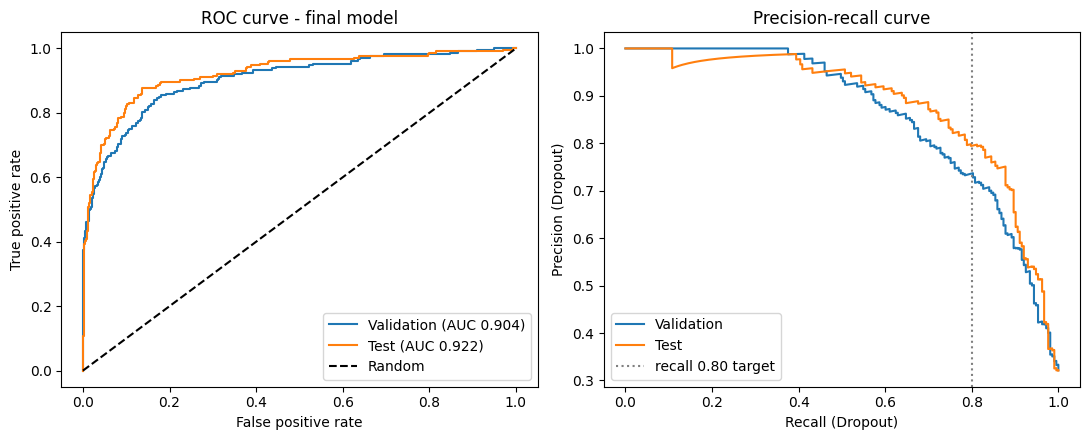

In [13]:
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for label, Xs, ys in [("Validation", X_val, y_val), ("Test", X_test, y_test)]:
    p = final.predict_proba(Xs)[:, 1]
    fpr, tpr, _ = roc_curve(ys, p)
    ax[0].plot(fpr, tpr, label=f"{label} (AUC {roc_auc_score(ys, p):.3f})")
    prec_, rec_, _ = precision_recall_curve(ys, p)
    ax[1].plot(rec_, prec_, label=label)

ax[0].plot([0, 1], [0, 1], "k--", label="Random")
ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve - final model")
ax[0].legend()
ax[1].axvline(0.80, color="grey", ls=":", label="recall 0.80 target")
ax[1].set(xlabel="Recall (Dropout)", ylabel="Precision (Dropout)", title="Precision-recall curve")
ax[1].legend()
plt.tight_layout()
plt.show()

## Hand-off checks
Confirms that the trained model and the three data splits are still in memory before the model is exported.

In [14]:
# Check whether the trained model and datasets are available
for name in ["final", "X_train", "y_train",
             "X_val", "y_val", "X_test", "y_test"]:
    print(f"{name}: {'Available' if name in globals() else 'Not found'}")

final: Available
X_train: Available
y_train: Available
X_val: Available
y_val: Available
X_test: Available
y_test: Available


## Export the model file
Re-saves the same fitted pipeline (the file already written in Task 7) and confirms that it exists. The file is then downloaded for use by `predictor.py` and the Streamlit app.

In [15]:
import os
import joblib

# Create the folder for model files
os.makedirs("model_artifacts", exist_ok=True)

# Save your trained model
model_path = "model_artifacts/dropout_pipeline_v1.joblib"
joblib.dump(final, model_path)

# Confirm the file was created
print("Model saved successfully!")
print("File path:", os.path.abspath(model_path))
print("File exists:", os.path.exists(model_path))
print("Model type:", type(final))

Model saved successfully!
File path: /content/model_artifacts/dropout_pipeline_v1.joblib
File exists: True
Model type: <class 'sklearn.pipeline.Pipeline'>


## Download the model and metadata files
Downloads the saved pipeline and its `metadata_v1.json` from Colab to the local machine. This cell only works inside Google Colab. Place both files in the app's `model_artifacts/` folder.

In [16]:
from google.colab import files

files.download("model_artifacts/dropout_pipeline_v1.joblib")
files.download("model_artifacts/metadata_v1.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Environment
The library versions used in this notebook, recorded for reproducibility. Run this cell in the same session and keep its output.

In [17]:
import sys, sklearn, pandas, numpy, xgboost, joblib
print('python', sys.version.split()[0])
for m in (sklearn, pandas, numpy, xgboost, joblib):
    print(m.__name__, m.__version__)

python 3.13.18
sklearn 1.6.1
pandas 2.2.3
numpy 2.4.6
xgboost 3.4.1
joblib 1.6.0
